**CUDA stands for Compute Unified Device Architecture. It is NVIDIA's parallel computing platform and programming model that allows programmers to execute computationally intensive portions of a program on the GPU.**

A CUDA program generally consists of two parts:

Host → CPU
Device → GPU

The CPU controls the overall program, while the GPU executes parallel portions of the computation

| CPU                                         | GPU                               |
| ------------------------------------------- | --------------------------------- |
| Small number of powerful cores              | Large number of simpler cores     |
| Good for sequential/control-intensive tasks | Good for massively parallel tasks |
| Optimized for low latency                   | Optimized for high throughput     |
| Executes relatively few threads             | Executes thousands of threads     |


CUDA Programming Model:

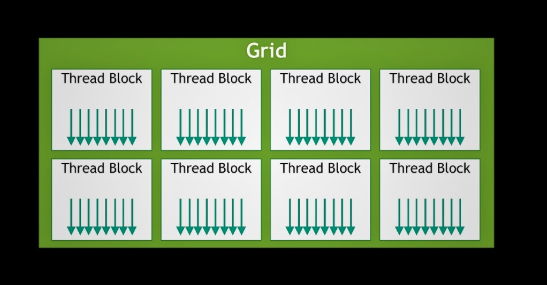

Thread: Smallest unit of execution.

Block: Collection of threads that can cooperate using shared memory and synchronization.

Grid: Collection of blocks launched for a kernel.

CPU Program
     
     ↓

Allocate/prepare data
     
     ↓

Copy data CPU → GPU
    
     ↓

Launch CUDA Kernel
     
     ↓

GPU performs computation
    
     ↓
     
Copy result GPU → CPU

In [1]:
%%writefile hello.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void helloCUDA()
{
    printf("Hello from GPU! Thread = %d\n", threadIdx.x);
}

int main()
{
    helloCUDA<<<1, 8>>>();

    cudaDeviceSynchronize();

    return 0;
}

Writing hello.cu


In [3]:
!nvcc hello.cu -o hello

In [4]:
!./hello

Hello from GPU! Thread = 0
Hello from GPU! Thread = 1
Hello from GPU! Thread = 2
Hello from GPU! Thread = 3
Hello from GPU! Thread = 4
Hello from GPU! Thread = 5
Hello from GPU! Thread = 6
Hello from GPU! Thread = 7


Understanding the CUDA Kernel:

__global__ void helloCUDA()

__global__ tells CUDA that: This function is executed on the GPU but called from the CPU.



A CUDA kernel is launched using:

kernel<<<number_of_blocks, threads_per_block>>>();

For example:

helloCUDA<<<1, 8>>>();

means:

Grid

 └──
 Block 0

     
      ├── Thread 0
      ├── Thread 1
      ├── Thread 2
      ├── Thread 3
      ├── Thread 4
      ├── Thread 5
      ├── Thread 6
      └── Thread 7

Display Thread ID

In [5]:
%%writefile thread_id.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void showThreadID()
{
    printf("Thread ID = %d\n", threadIdx.x);
}

int main()
{
    showThreadID<<<1, 8>>>();

    cudaDeviceSynchronize();

    return 0;
}

Writing thread_id.cu


In [6]:
!nvcc thread_id.cu -o thread_id
!./thread_id

Thread ID = 0
Thread ID = 1
Thread ID = 2
Thread ID = 3
Thread ID = 4
Thread ID = 5
Thread ID = 6
Thread ID = 7


Blocks and Threads:
launch multiple blocks.

showThreadID<<<3, 4>>();

This means:

Grid

│

├── Block 0 → 4 threads

├── Block 1 → 4 threads

└── Block 2 → 4 threads

However, threadIdx.x starts from 0 in every block.

Therefore, we also need:

blockIdx.x

In [7]:
%%writefile block_thread.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void showIDs()
{
    printf("Block = %d, Thread = %d\n",
           blockIdx.x,
           threadIdx.x);
}

int main()
{
    showIDs<<<3, 4>>>();

    cudaDeviceSynchronize();

    return 0;
}

Writing block_thread.cu


In [8]:
!nvcc block_thread.cu -o block_thread
!./block_thread

Block = 2, Thread = 0
Block = 2, Thread = 1
Block = 2, Thread = 2
Block = 2, Thread = 3
Block = 0, Thread = 0
Block = 0, Thread = 1
Block = 0, Thread = 2
Block = 0, Thread = 3
Block = 1, Thread = 0
Block = 1, Thread = 1
Block = 1, Thread = 2
Block = 1, Thread = 3


Global Thread ID:

We usually need a unique ID for every thread in the entire grid.

The formula is:

$$ globalID = blockIdx.x \times blockDim.x + threadIdx.x $$

where:

blockIdx.x = block number
blockDim.x = number of threads per block
threadIdx.x = thread number inside block

For Example: <<<3,4>>>
| Block | Thread | Global ID |
| ----: | -----: | --------: |
|     0 |      0 |         0 |
|     0 |      1 |         1 |
|     0 |      2 |         2 |
|     0 |      3 |         3 |
|     1 |      0 |         4 |
|     1 |      1 |         5 |
|     1 |      2 |         6 |
|     1 |      3 |         7 |
|     2 |      0 |         8 |
|     2 |      1 |         9 |
|     2 |      2 |        10 |
|     2 |      3 |        11 |


In [9]:
%%writefile global_id.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void showGlobalID()
{
    int id = blockIdx.x * blockDim.x + threadIdx.x;

    printf("Block = %d, Thread = %d, Global ID = %d\n",
           blockIdx.x,
           threadIdx.x,
           id);
}

int main()
{
    showGlobalID<<<3, 4>>>();

    cudaDeviceSynchronize();

    return 0;
}

Writing global_id.cu


In [10]:
!nvcc global_id.cu -o global_id
!./global_id

Block = 2, Thread = 0, Global ID = 8
Block = 2, Thread = 1, Global ID = 9
Block = 2, Thread = 2, Global ID = 10
Block = 2, Thread = 3, Global ID = 11
Block = 0, Thread = 0, Global ID = 0
Block = 0, Thread = 1, Global ID = 1
Block = 0, Thread = 2, Global ID = 2
Block = 0, Thread = 3, Global ID = 3
Block = 1, Thread = 0, Global ID = 4
Block = 1, Thread = 1, Global ID = 5
Block = 1, Thread = 2, Global ID = 6
Block = 1, Thread = 3, Global ID = 7


Vector Addition:

Given:

$$ A=[a_0,a_1,a_2,...] $$ $$ B=[b_0,b_1,b_2,...] $$

we calculate:

$$ C[i]=A[i]+B[i] $$

The important observation is:

Every element can be calculated independently.

Therefore, every element can be assigned to a separate GPU thread.

Thread 0 → C[0] = A[0] + B[0]

Thread 1 → C[1] = A[1] + B[1]

Thread 2 → C[2] = A[2] + B[2]

Thread 3 → C[3] = A[3] + B[3]

...

In [2]:
%%writefile vector_add.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void vectorAdd(int *A, int *B, int *C, int N)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < N)
    {
        C[i] = A[i] + B[i];
    }
}

int main()
{
    int N = 10;
    int size = N * sizeof(int);

    int h_A[10] = {1,2,3,4,5,6,7,8,9,10};
    int h_B[10] = {10,20,30,40,50,60,70,80,90,100};
    int h_C[10];

    int *d_A, *d_B, *d_C;

    // Allocate GPU memory
    cudaMalloc((void**)&d_A, size);
    cudaMalloc((void**)&d_B, size);
    cudaMalloc((void**)&d_C, size);

    // Copy data CPU → GPU
    cudaMemcpy(d_A, h_A, size, cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, h_B, size, cudaMemcpyHostToDevice);

    // Launch kernel
    int threads = 256;
    int blocks = (N + threads - 1) / threads;

    vectorAdd<<<blocks, threads>>>(d_A, d_B, d_C, N);

    cudaDeviceSynchronize();

    // Copy result GPU → CPU
    cudaMemcpy(h_C, d_C, size, cudaMemcpyDeviceToHost);

    // Display result
    printf("Result:\n");

    for (int i = 0; i < N; i++)
    {
        printf("%d ", h_C[i]);
    }

    printf("\n");

    // Free GPU memory
    cudaFree(d_A);
    cudaFree(d_B);
    cudaFree(d_C);

    return 0;
}

Writing vector_add.cu


In [12]:
!nvcc vector_add.cu -o vector_add

In [13]:
!./vector_add

Result:
11 22 33 44 55 66 77 88 99 110 


**Matrix Matrix Addition:**

For matrices:

$$ C_{ij}=A_{ij}+B_{ij} $$

For a matrix, we use 2D thread indexing.

int row = blockIdx.y * blockDim.y + threadIdx.y;

int col = blockIdx.x * blockDim.x + threadIdx.x;

Each thread handles one matrix element.

In [2]:
%%writefile matrix_add.cu

#include <stdio.h>
#include <cuda_runtime.h>

#define N 4

__global__ void matrixAdd(int A[N][N],
                          int B[N][N],
                          int C[N][N])
{
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N)
    {
        C[row][col] = A[row][col] + B[row][col];
    }
}

int main()
{
    int A[N][N] = {
        {1,2,3,4},
        {5,6,7,8},
        {9,10,11,12},
        {13,14,15,16}
    };

    int B[N][N] = {
        {10,10,10,10},
        {10,10,10,10},
        {10,10,10,10},
        {10,10,10,10}
    };

    int C[N][N];

    int (*d_A)[N];
    int (*d_B)[N];
    int (*d_C)[N];

    cudaMalloc(&d_A, sizeof(A));
    cudaMalloc(&d_B, sizeof(B));
    cudaMalloc(&d_C, sizeof(C));

    cudaMemcpy(d_A, A, sizeof(A), cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B, sizeof(B), cudaMemcpyHostToDevice);

    dim3 threads(2,2);
    dim3 blocks(2,2);

    matrixAdd<<<blocks, threads>>>(d_A,d_B,d_C);

    cudaDeviceSynchronize();

    cudaMemcpy(C, d_C, sizeof(C), cudaMemcpyDeviceToHost);

    printf("Result:\n");

    for(int i=0;i<N;i++)
    {
        for(int j=0;j<N;j++)
        {
            printf("%d ", C[i][j]);
        }

        printf("\n");
    }

    cudaFree(d_A);
    cudaFree(d_B);
    cudaFree(d_C);

    return 0;
}

Overwriting matrix_add.cu


In [3]:
!nvcc matrix_add.cu -o matrix_add
!./matrix_add

Result:
11 12 13 14 
15 16 17 18 
19 20 21 22 
23 24 25 26 


**Matrix Multiplication**

Mathematical formulation
$$ C_{ij}=\sum_{k=0}^{N-1} A_{ik}B_{kj} $$

For example:

$$ C_{00}=A_{00}B_{00}+A_{01}B_{10}+A_{02}B_{20} $$

Each GPU thread calculates one element of C.

In [ ]:
%%writefile matrix_mul.cu

#include <stdio.h>
#include <cuda_runtime.h>

#define N 3

__global__ void matrixMul(int A[N][N],
                          int B[N][N],
                          int C[N][N])
{
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N)
    {
        int sum = 0;

        for(int k = 0; k < N; k++)
        {
            sum += A[row][k] * B[k][col];
        }

        C[row][col] = sum;
    }
}

int main()
{
    int A[N][N] = {
        {1,2,3},
        {4,5,6},
        {7,8,9}
    };

    int B[N][N] = {
        {9,8,7},
        {6,5,4},
        {3,2,1}
    };

    int C[N][N];

    int (*d_A)[N];
    int (*d_B)[N];
    int (*d_C)[N];

    cudaMalloc(&d_A, sizeof(A));
    cudaMalloc(&d_B, sizeof(B));
    cudaMalloc(&d_C, sizeof(C));

    cudaMemcpy(d_A,A,sizeof(A),cudaMemcpyHostToDevice);
    cudaMemcpy(d_B,B,sizeof(B),cudaMemcpyHostToDevice);

    dim3 threads(16,16);
    dim3 blocks((N+15)/16,(N+15)/16);

    matrixMul<<<blocks,threads>>>(d_A,d_B,d_C);

    cudaDeviceSynchronize();

    cudaMemcpy(C,d_C,sizeof(C),cudaMemcpyDeviceToHost);

    printf("Result:\n");

    for(int i=0;i<N;i++)
    {
        for(int j=0;j<N;j++)
        {
            printf("%d ",C[i][j]);
        }

        printf("\n");
    }

    cudaFree(d_A);
    cudaFree(d_B);
    cudaFree(d_C);

    return 0;
}

In [ ]:
!nvcc matrix_mul.cu -o matrix_mul
!./matrix_mul

Important CUDA C Functions:

| CUDA C                    | Meaning                     |
| ------------------------- | --------------------------- |
| `__global__`              | GPU kernel called from CPU  |
| `__device__`              | Function executed on GPU    |
| `__host__`                | Function executed on CPU    |
| `threadIdx.x`             | Thread ID within block      |
| `blockIdx.x`              | Block ID                    |
| `blockDim.x`              | Number of threads per block |
| `gridDim.x`               | Number of blocks            |
| `cudaMalloc()`            | Allocate GPU memory         |
| `cudaFree()`              | Free GPU memory             |
| `cudaMemcpy()`            | Copy data                   |
| `cudaDeviceSynchronize()` | Wait for GPU                |
| `<<<blocks,threads>>>`    | Kernel launch configuration |


Important Formula:

For global ID:
$$ \boxed{ globalID=blockIdx.x\times blockDim.x+threadIdx.x } $$

For 2D:

$$ \boxed{ row=blockIdx.y\times blockDim.y+threadIdx.y } $$
$$ \boxed{col=blockIdx.x×blockDim.x+threadIdx.x}$$
	​


Practice Programs

1. Vector Vector Addition:

In [8]:
%%writefile vector_add_large.cu

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <time.h>
#include <cuda_runtime.h>

/* ---------------------------------------------------------
   CUDA Error Checking Macro
   --------------------------------------------------------- */
#define CHECK_CUDA(call)                                      \
do {                                                         \
    cudaError_t error = call;                                \
    if (error != cudaSuccess) {                              \
        fprintf(stderr, "CUDA Error: %s\n",                 \
                cudaGetErrorString(error));                  \
        exit(EXIT_FAILURE);                                  \
    }                                                        \
} while (0)


/* ---------------------------------------------------------
   GPU Kernel
   Each thread computes one element of C
   --------------------------------------------------------- */
__global__ void vectorAdd(float *A, float *B, float *C, int N)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < N)
    {
        C[i] = A[i] + B[i];
    }
}


/* ---------------------------------------------------------
   CPU Vector Addition
   --------------------------------------------------------- */
void vectorAddCPU(float *A, float *B, float *C, int N)
{
    for (int i = 0; i < N; i++)
    {
        C[i] = A[i] + B[i];
    }
}


/* ---------------------------------------------------------
   Main Function
   --------------------------------------------------------- */
int main()
{
    /* Large vector */
    int N = 10000000;

    size_t size = N * sizeof(float);

    printf("=============================================\n");
    printf("       CUDA VECTOR ADDITION\n");
    printf("=============================================\n");
    printf("Number of elements : %d\n", N);

    /* -----------------------------------------------------
       Host memory allocation
       ----------------------------------------------------- */
    float *h_A = (float *)malloc(size);
    float *h_B = (float *)malloc(size);
    float *h_C_CPU = (float *)malloc(size);
    float *h_C_GPU = (float *)malloc(size);

    /* Initialize input */
    for (int i = 0; i < N; i++)
    {
        h_A[i] = 1.0f;
        h_B[i] = 2.0f;
    }


    /* -----------------------------------------------------
       CPU Execution
       ----------------------------------------------------- */
    clock_t cpu_start = clock();

    vectorAddCPU(h_A, h_B, h_C_CPU, N);

    clock_t cpu_end = clock();

    double cpu_time =
        ((double)(cpu_end - cpu_start) / CLOCKS_PER_SEC) * 1000.0;


    /* -----------------------------------------------------
       Device memory allocation
       ----------------------------------------------------- */
    float *d_A, *d_B, *d_C;

    CHECK_CUDA(cudaMalloc((void **)&d_A, size));
    CHECK_CUDA(cudaMalloc((void **)&d_B, size));
    CHECK_CUDA(cudaMalloc((void **)&d_C, size));


    /* -----------------------------------------------------
       CUDA Configuration
       ----------------------------------------------------- */
    int threads = 256;
    int blocks = (N + threads - 1) / threads;

    printf("Threads per block  : %d\n", threads);
    printf("Number of blocks   : %d\n", blocks);


    /* -----------------------------------------------------
       CUDA Events for GPU timing
       ----------------------------------------------------- */
    cudaEvent_t start, stop;

    CHECK_CUDA(cudaEventCreate(&start));
    CHECK_CUDA(cudaEventCreate(&stop));

    float h2d_time;
    float kernel_time;
    float d2h_time;


    /* -----------------------------------------------------
       Host → Device transfer
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        d_A, h_A, size, cudaMemcpyHostToDevice));

    CHECK_CUDA(cudaMemcpy(
        d_B, h_B, size, cudaMemcpyHostToDevice));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &h2d_time, start, stop));


    /* -----------------------------------------------------
       GPU Kernel Execution
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    vectorAdd<<<blocks, threads>>>(d_A, d_B, d_C, N);

    CHECK_CUDA(cudaGetLastError());
    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &kernel_time, start, stop));


    /* -----------------------------------------------------
       Device → Host transfer
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        h_C_GPU, d_C, size, cudaMemcpyDeviceToHost));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &d2h_time, start, stop));


    /* -----------------------------------------------------
       Total GPU time
       ----------------------------------------------------- */
    float total_gpu_time =
        h2d_time + kernel_time + d2h_time;


    /* -----------------------------------------------------
       Verify Result
       ----------------------------------------------------- */
    int correct = 1;

    for (int i = 0; i < N; i++)
    {
        if (fabs(h_C_CPU[i] - h_C_GPU[i]) > 1e-5)
        {
            correct = 0;
            break;
        }
    }


    /* -----------------------------------------------------
       Performance calculations
       ----------------------------------------------------- */

    double kernel_speedup =
        cpu_time / kernel_time;

    double overall_speedup =
        cpu_time / total_gpu_time;

    /* Vector addition:
       2 reads + 1 write = 3 floating-point values
    */
    double bytes =
        3.0 * N * sizeof(float);

    double bandwidth =
        bytes / (kernel_time / 1000.0) / 1e9;


    /* -----------------------------------------------------
       Display Results
       ----------------------------------------------------- */
    printf("\n--------------- PERFORMANCE ----------------\n");

    printf("CPU Time           : %.3f ms\n", cpu_time);
    printf("Host → Device      : %.3f ms\n", h2d_time);
    printf("Kernel Time        : %.3f ms\n", kernel_time);
    printf("Device → Host      : %.3f ms\n", d2h_time);
    printf("Total GPU Time     : %.3f ms\n", total_gpu_time);

    printf("\nKernel Speedup     : %.2fx\n",
           kernel_speedup);

    printf("Overall Speedup    : %.2fx\n",
           overall_speedup);

    printf("Effective Bandwidth: %.2f GB/s\n",
           bandwidth);

    printf("\nResult Verification: ");

    if (correct)
        printf("PASSED\n");
    else
        printf("FAILED\n");


    /* -----------------------------------------------------
       Free memory
       ----------------------------------------------------- */
    free(h_A);
    free(h_B);
    free(h_C_CPU);
    free(h_C_GPU);

    CHECK_CUDA(cudaFree(d_A));
    CHECK_CUDA(cudaFree(d_B));
    CHECK_CUDA(cudaFree(d_C));

    CHECK_CUDA(cudaEventDestroy(start));
    CHECK_CUDA(cudaEventDestroy(stop));

    return 0;
}

Overwriting vector_add_large.cu


In [9]:
!nvcc vector_add_large.cu -o vector_add_large
!./vector_add_large

       CUDA VECTOR ADDITION
Number of elements : 10000000
Threads per block  : 256
Number of blocks   : 39063

--------------- PERFORMANCE ----------------
CPU Time           : 46.625 ms
Host → Device      : 17.254 ms
Kernel Time        : 0.552 ms
Device → Host      : 25.980 ms
Total GPU Time     : 43.786 ms

Kernel Speedup     : 84.48x
Overall Speedup    : 1.06x
Effective Bandwidth: 217.42 GB/s

Result Verification: PASSED


For matrix addition:

$$ C_{ij}=A_{ij}+B_{ij} $$

We can use a 2D grid and 2D blocks.

For a large matrix, I suggest:

$$ 4096\times4096 $$

This gives:

$$ 16,777,216 $$

matrix elements.

In [10]:
%%writefile matrix_add_large.cu

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <time.h>
#include <cuda_runtime.h>

#define CHECK_CUDA(call)                                      \
do {                                                         \
    cudaError_t error = call;                                \
    if (error != cudaSuccess) {                              \
        fprintf(stderr, "CUDA Error: %s\n",                 \
                cudaGetErrorString(error));                  \
        exit(EXIT_FAILURE);                                  \
    }                                                        \
} while (0)


/* ---------------------------------------------------------
   GPU Kernel
   --------------------------------------------------------- */
__global__ void matrixAdd(float *A, float *B, float *C, int N)
{
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N)
    {
        int index = row * N + col;

        C[index] = A[index] + B[index];
    }
}


/* ---------------------------------------------------------
   CPU Matrix Addition
   --------------------------------------------------------- */
void matrixAddCPU(float *A, float *B, float *C, int N)
{
    for (int row = 0; row < N; row++)
    {
        for (int col = 0; col < N; col++)
        {
            int index = row * N + col;

            C[index] = A[index] + B[index];
        }
    }
}


/* ---------------------------------------------------------
   Main Function
   --------------------------------------------------------- */
int main()
{
    /* 4096 × 4096 matrix */
    int N = 4096;

    size_t elements = (size_t)N * N;
    size_t size = elements * sizeof(float);

    printf("=============================================\n");
    printf("       CUDA MATRIX ADDITION\n");
    printf("=============================================\n");

    printf("Matrix size        : %d x %d\n", N, N);
    printf("Total elements     : %zu\n", elements);
    printf("Memory per matrix  : %.2f MB\n",
           size / (1024.0 * 1024.0));


    /* -----------------------------------------------------
       Host Memory
       ----------------------------------------------------- */
    float *h_A = (float *)malloc(size);
    float *h_B = (float *)malloc(size);
    float *h_C_CPU = (float *)malloc(size);
    float *h_C_GPU = (float *)malloc(size);


    /* Initialize matrices */
    for (size_t i = 0; i < elements; i++)
    {
        h_A[i] = 1.0f;
        h_B[i] = 2.0f;
    }


    /* -----------------------------------------------------
       CPU Execution
       ----------------------------------------------------- */
    clock_t cpu_start = clock();

    matrixAddCPU(h_A, h_B, h_C_CPU, N);

    clock_t cpu_end = clock();

    double cpu_time =
        ((double)(cpu_end - cpu_start) / CLOCKS_PER_SEC) * 1000.0;


    /* -----------------------------------------------------
       Device Memory
       ----------------------------------------------------- */
    float *d_A, *d_B, *d_C;

    CHECK_CUDA(cudaMalloc((void **)&d_A, size));
    CHECK_CUDA(cudaMalloc((void **)&d_B, size));
    CHECK_CUDA(cudaMalloc((void **)&d_C, size));


    /* -----------------------------------------------------
       CUDA Configuration
       ----------------------------------------------------- */
    dim3 threads(16, 16);

    dim3 blocks(
        (N + threads.x - 1) / threads.x,
        (N + threads.y - 1) / threads.y
    );

    printf("\nThreads per block : %d x %d\n",
           threads.x, threads.y);

    printf("Grid              : %d x %d\n",
           blocks.x, blocks.y);


    /* -----------------------------------------------------
       CUDA Events
       ----------------------------------------------------- */
    cudaEvent_t start, stop;

    CHECK_CUDA(cudaEventCreate(&start));
    CHECK_CUDA(cudaEventCreate(&stop));

    float h2d_time;
    float kernel_time;
    float d2h_time;


    /* -----------------------------------------------------
       Host → Device
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        d_A, h_A, size, cudaMemcpyHostToDevice));

    CHECK_CUDA(cudaMemcpy(
        d_B, h_B, size, cudaMemcpyHostToDevice));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &h2d_time, start, stop));


    /* -----------------------------------------------------
       GPU Kernel
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    matrixAdd<<<blocks, threads>>>(
        d_A, d_B, d_C, N);

    CHECK_CUDA(cudaGetLastError());

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &kernel_time, start, stop));


    /* -----------------------------------------------------
       Device → Host
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        h_C_GPU, d_C, size,
        cudaMemcpyDeviceToHost));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &d2h_time, start, stop));


    /* -----------------------------------------------------
       Total GPU Time
       ----------------------------------------------------- */
    float total_gpu_time =
        h2d_time + kernel_time + d2h_time;


    /* -----------------------------------------------------
       Verify Result
       ----------------------------------------------------- */
    int correct = 1;

    for (size_t i = 0; i < elements; i++)
    {
        if (fabs(h_C_CPU[i] - h_C_GPU[i]) > 1e-5)
        {
            correct = 0;
            break;
        }
    }


    /* -----------------------------------------------------
       Performance
       ----------------------------------------------------- */
    double kernel_speedup =
        cpu_time / kernel_time;

    double overall_speedup =
        cpu_time / total_gpu_time;


    /* 2 reads + 1 write */
    double bytes =
        3.0 * elements * sizeof(float);

    double bandwidth =
        bytes / (kernel_time / 1000.0) / 1e9;


    /* -----------------------------------------------------
       Display
       ----------------------------------------------------- */
    printf("\n--------------- PERFORMANCE ----------------\n");

    printf("CPU Time           : %.3f ms\n",
           cpu_time);

    printf("Host → Device      : %.3f ms\n",
           h2d_time);

    printf("Kernel Time        : %.3f ms\n",
           kernel_time);

    printf("Device → Host      : %.3f ms\n",
           d2h_time);

    printf("Total GPU Time     : %.3f ms\n",
           total_gpu_time);

    printf("\nKernel Speedup     : %.2fx\n",
           kernel_speedup);

    printf("Overall Speedup    : %.2fx\n",
           overall_speedup);

    printf("Effective Bandwidth: %.2f GB/s\n",
           bandwidth);

    printf("\nResult Verification: ");

    if (correct)
        printf("PASSED\n");
    else
        printf("FAILED\n");


    /* -----------------------------------------------------
       Free Memory
       ----------------------------------------------------- */
    free(h_A);
    free(h_B);
    free(h_C_CPU);
    free(h_C_GPU);

    CHECK_CUDA(cudaFree(d_A));
    CHECK_CUDA(cudaFree(d_B));
    CHECK_CUDA(cudaFree(d_C));

    CHECK_CUDA(cudaEventDestroy(start));
    CHECK_CUDA(cudaEventDestroy(stop));

    return 0;
}

Overwriting matrix_add_large.cu


In [11]:
!nvcc matrix_add_large.cu -o matrix_add_large
!./matrix_add_large

       CUDA MATRIX ADDITION
Matrix size        : 4096 x 4096
Total elements     : 16777216
Memory per matrix  : 64.00 MB

Threads per block : 16 x 16
Grid              : 256 x 256

--------------- PERFORMANCE ----------------
CPU Time           : 81.806 ms
Host → Device      : 28.704 ms
Kernel Time        : 0.985 ms
Device → Host      : 44.590 ms
Total GPU Time     : 74.278 ms

Kernel Speedup     : 83.05x
Overall Speedup    : 1.10x
Effective Bandwidth: 204.38 GB/s

Result Verification: PASSED


The naïve algorithm is:

$$ C_{ij}=\sum_{k=0}^{N-1}A_{ik}B_{kj} $$

For an \(N\times N\) matrix, the number of operations is approximately:

$$ N^3 $$

So:
| Matrix      | Approx. iterations |
| ----------- | -----------------: |
| 256 × 256   |       16.8 million |
| 512 × 512   |        134 million |
| 1024 × 1024 |       1.07 billion |
| 2048 × 2048 |       8.59 billion |
| 4096 × 4096 |       68.7 billion |


In [12]:
%%writefile matrix_mul_large.cu

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <time.h>
#include <cuda_runtime.h>

#define CHECK_CUDA(call)                                      \
do {                                                         \
    cudaError_t error = call;                                \
    if (error != cudaSuccess) {                              \
        fprintf(stderr, "CUDA Error: %s\n",                 \
                cudaGetErrorString(error));                  \
        exit(EXIT_FAILURE);                                  \
    }                                                        \
} while (0)


/* ---------------------------------------------------------
   GPU Matrix Multiplication Kernel

   Each thread computes one element of C
   --------------------------------------------------------- */
__global__ void matrixMul(float *A,
                          float *B,
                          float *C,
                          int N)
{
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N)
    {
        float sum = 0.0f;

        for (int k = 0; k < N; k++)
        {
            sum += A[row * N + k] *
                   B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}


/* ---------------------------------------------------------
   CPU Matrix Multiplication
   --------------------------------------------------------- */
void matrixMulCPU(float *A,
                  float *B,
                  float *C,
                  int N)
{
    for (int row = 0; row < N; row++)
    {
        for (int col = 0; col < N; col++)
        {
            float sum = 0.0f;

            for (int k = 0; k < N; k++)
            {
                sum += A[row * N + k] *
                       B[k * N + col];
            }

            C[row * N + col] = sum;
        }
    }
}


/* ---------------------------------------------------------
   Main Function
   --------------------------------------------------------- */
int main()
{
    /*
       Start with 1024 × 1024.

       If CPU execution is too slow,
       try 512 × 512.
    */
    int N = 1024;

    size_t elements = (size_t)N * N;
    size_t size = elements * sizeof(float);

    printf("=============================================\n");
    printf("       CUDA MATRIX MULTIPLICATION\n");
    printf("=============================================\n");

    printf("Matrix size        : %d x %d\n",
           N, N);

    printf("Total elements     : %zu\n",
           elements);

    printf("Memory per matrix  : %.2f MB\n",
           size / (1024.0 * 1024.0));


    /* -----------------------------------------------------
       Host Memory
       ----------------------------------------------------- */
    float *h_A = (float *)malloc(size);
    float *h_B = (float *)malloc(size);
    float *h_C_CPU = (float *)malloc(size);
    float *h_C_GPU = (float *)malloc(size);


    /* -----------------------------------------------------
       Initialize Matrices
       ----------------------------------------------------- */
    for (size_t i = 0; i < elements; i++)
    {
        h_A[i] = 1.0f;
        h_B[i] = 2.0f;
    }


    /* -----------------------------------------------------
       CPU Matrix Multiplication
       ----------------------------------------------------- */
    printf("\nRunning CPU multiplication...\n");

    clock_t cpu_start = clock();

    matrixMulCPU(
        h_A,
        h_B,
        h_C_CPU,
        N
    );

    clock_t cpu_end = clock();

    double cpu_time =
        ((double)(cpu_end - cpu_start)
         / CLOCKS_PER_SEC) * 1000.0;


    /* -----------------------------------------------------
       Device Memory
       ----------------------------------------------------- */
    float *d_A;
    float *d_B;
    float *d_C;

    CHECK_CUDA(cudaMalloc(
        (void **)&d_A, size));

    CHECK_CUDA(cudaMalloc(
        (void **)&d_B, size));

    CHECK_CUDA(cudaMalloc(
        (void **)&d_C, size));


    /* -----------------------------------------------------
       CUDA Configuration
       ----------------------------------------------------- */
    dim3 threads(16, 16);

    dim3 blocks(
        (N + threads.x - 1) / threads.x,
        (N + threads.y - 1) / threads.y
    );

    printf("\nThreads per block : %d x %d\n",
           threads.x, threads.y);

    printf("Grid              : %d x %d\n",
           blocks.x, blocks.y);


    /* -----------------------------------------------------
       CUDA Events
       ----------------------------------------------------- */
    cudaEvent_t start, stop;

    CHECK_CUDA(cudaEventCreate(&start));
    CHECK_CUDA(cudaEventCreate(&stop));

    float h2d_time;
    float kernel_time;
    float d2h_time;


    /* -----------------------------------------------------
       Host → Device
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        d_A,
        h_A,
        size,
        cudaMemcpyHostToDevice
    ));

    CHECK_CUDA(cudaMemcpy(
        d_B,
        h_B,
        size,
        cudaMemcpyHostToDevice
    ));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &h2d_time,
        start,
        stop
    ));


    /* -----------------------------------------------------
       GPU Matrix Multiplication
       ----------------------------------------------------- */
    printf("\nRunning GPU multiplication...\n");

    CHECK_CUDA(cudaEventRecord(start));

    matrixMul<<<blocks, threads>>>(
        d_A,
        d_B,
        d_C,
        N
    );

    CHECK_CUDA(cudaGetLastError());

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &kernel_time,
        start,
        stop
    ));


    /* -----------------------------------------------------
       Device → Host
       ----------------------------------------------------- */
    CHECK_CUDA(cudaEventRecord(start));

    CHECK_CUDA(cudaMemcpy(
        h_C_GPU,
        d_C,
        size,
        cudaMemcpyDeviceToHost
    ));

    CHECK_CUDA(cudaEventRecord(stop));
    CHECK_CUDA(cudaEventSynchronize(stop));

    CHECK_CUDA(cudaEventElapsedTime(
        &d2h_time,
        start,
        stop
    ));


    /* -----------------------------------------------------
       Total GPU Time
       ----------------------------------------------------- */
    float total_gpu_time =
        h2d_time +
        kernel_time +
        d2h_time;


    /* -----------------------------------------------------
       Verify Results
       ----------------------------------------------------- */
    int correct = 1;

    for (size_t i = 0; i < elements; i++)
    {
        if (fabsf(h_C_CPU[i] -
                  h_C_GPU[i]) > 1e-3f)
        {
            correct = 0;
            break;
        }
    }


    /* -----------------------------------------------------
       Performance Metrics
       ----------------------------------------------------- */

    double kernel_speedup =
        cpu_time / kernel_time;

    double overall_speedup =
        cpu_time / total_gpu_time;


    /*
       Matrix multiplication performs approximately:

       2 × N³ floating-point operations

       because every multiplication is followed
       by an addition.
    */
    double operations =
        2.0 * N * N * N;

    double gflops =
        operations /
        (kernel_time / 1000.0) /
        1e9;


    /* -----------------------------------------------------
       Display Results
       ----------------------------------------------------- */
    printf("\n--------------- PERFORMANCE ----------------\n");

    printf("CPU Time           : %.3f ms\n",
           cpu_time);

    printf("Host → Device      : %.3f ms\n",
           h2d_time);

    printf("Kernel Time        : %.3f ms\n",
           kernel_time);

    printf("Device → Host      : %.3f ms\n",
           d2h_time);

    printf("Total GPU Time     : %.3f ms\n",
           total_gpu_time);

    printf("\nKernel Speedup     : %.2fx\n",
           kernel_speedup);

    printf("Overall Speedup    : %.2fx\n",
           overall_speedup);

    printf("GPU Performance    : %.2f GFLOPS\n",
           gflops);

    printf("\nResult Verification: ");

    if (correct)
        printf("PASSED\n");
    else
        printf("FAILED\n");


    /* -----------------------------------------------------
       Free Memory
       ----------------------------------------------------- */
    free(h_A);
    free(h_B);
    free(h_C_CPU);
    free(h_C_GPU);

    CHECK_CUDA(cudaFree(d_A));
    CHECK_CUDA(cudaFree(d_B));
    CHECK_CUDA(cudaFree(d_C));

    CHECK_CUDA(cudaEventDestroy(start));
    CHECK_CUDA(cudaEventDestroy(stop));

    return 0;
}

Writing matrix_mul_large.cu


In [13]:
!nvcc matrix_mul_large.cu -o matrix_mul_large
!./matrix_mul_large

       CUDA MATRIX MULTIPLICATION
Matrix size        : 1024 x 1024
Total elements     : 1048576
Memory per matrix  : 4.00 MB

Running CPU multiplication...

Threads per block : 16 x 16
Grid              : 64 x 64

Running GPU multiplication...

--------------- PERFORMANCE ----------------
CPU Time           : 8436.729 ms
Host → Device      : 2.124 ms
Kernel Time        : 7.369 ms
Device → Host      : 2.850 ms
Total GPU Time     : 12.343 ms

Kernel Speedup     : 1144.89x
Overall Speedup    : 683.51x
GPU Performance    : 291.42 GFLOPS

Result Verification: PASSED


What is the problem?

Consider a small example:

$$ A= \begin{bmatrix} A_{00}&A_{01}&A_{02}&A_{03}\\ A_{10}&A_{11}&A_{12}&A_{13}\\ A_{20}&A_{21}&A_{22}&A_{23}\\ A_{30}&A_{31}&A_{32}&A_{33} \end{bmatrix} $$

and

$$ B= \begin{bmatrix} B_{00}&B_{01}&B_{02}&B_{03}\\ B_{10}&B_{11}&B_{12}&B_{13}\\ B_{20}&B_{21}&B_{22}&B_{23}\\ B_{30}&B_{31}&B_{32}&B_{33} \end{bmatrix} $$

Suppose four threads calculate:

Thread 0 → C[0][0]

Thread 1 → C[0][1]

Thread 2 → C[0][2]

Thread 3 → C[0][3]

For calculating the first row of C, they all need:

A[0][0]

A[0][1]

A[0][2]

A[0][3]


So the same A values are being used repeatedly.

Similarly, different threads need overlapping portions of B.

Global memory has relatively high latency compared with on-chip memories.

Can a group of threads load data once and reuse it?

That is exactly where shared memory comes in.

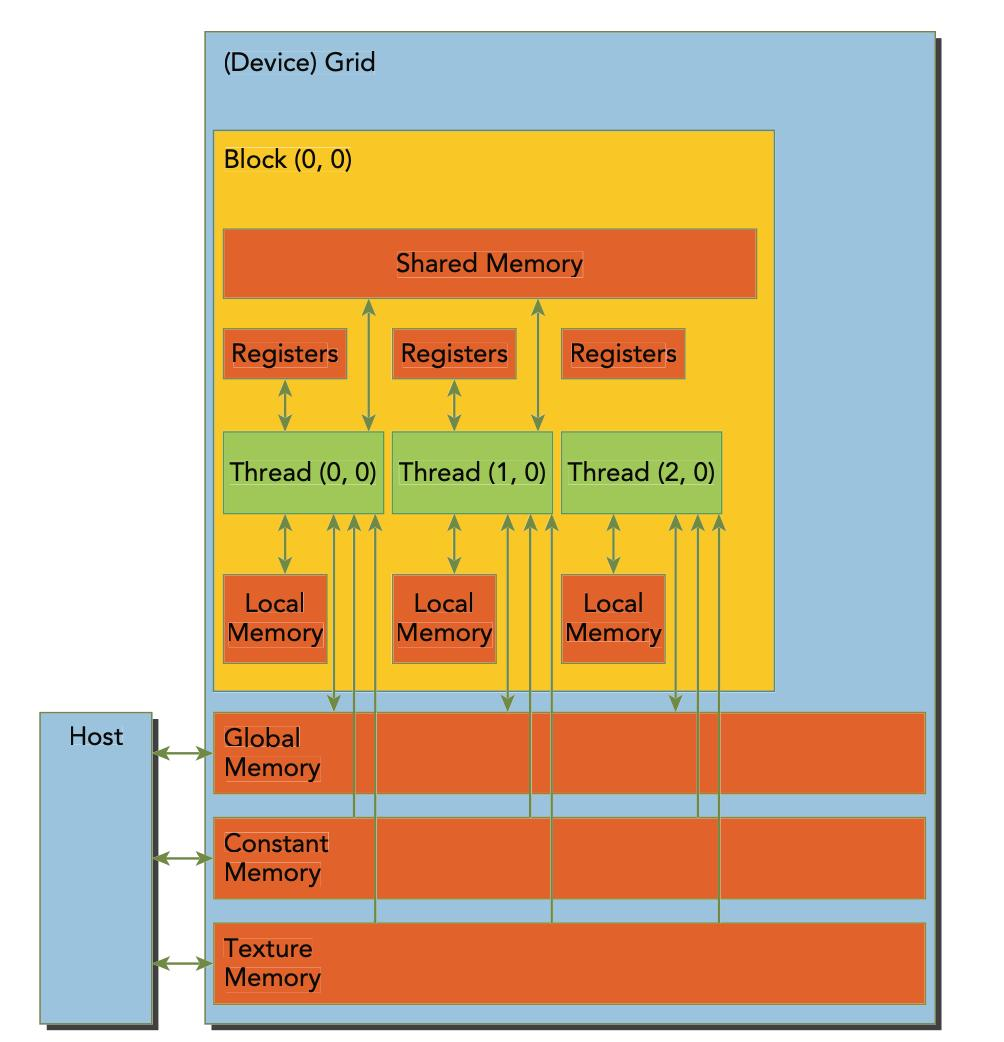


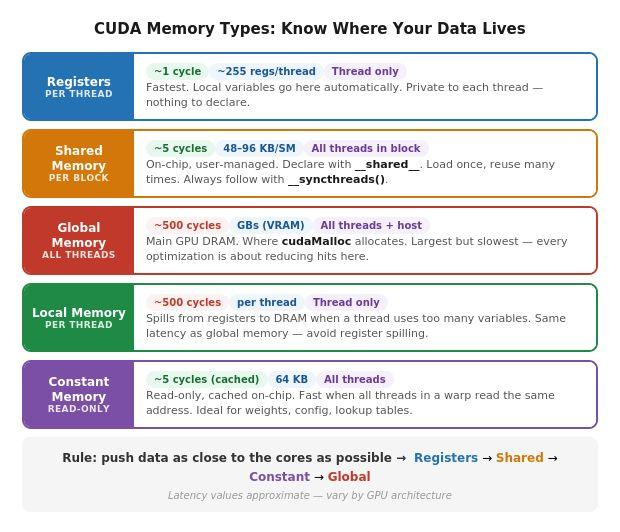

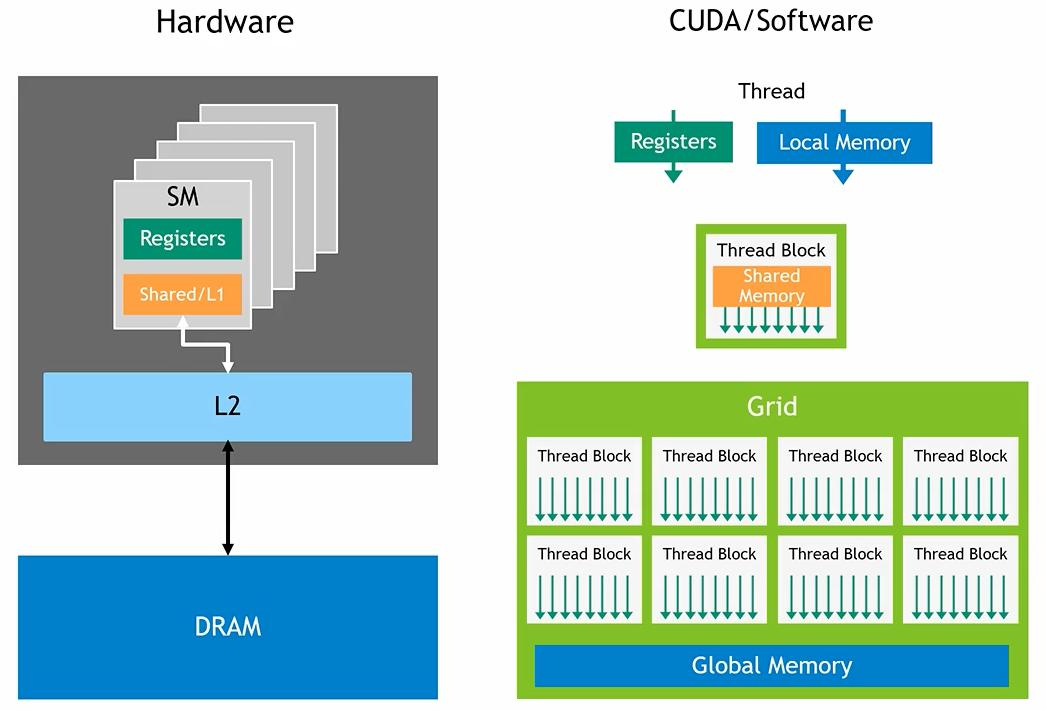

| Memory              | Location           | Accessible by         | Relative speed                        | Lifetime    |
| ------------------- | ------------------ | --------------------- | ------------------------------------- | ----------- |
| **Registers**       | On-chip            | Individual thread     | Very fast                             | Thread      |
| **Shared Memory**   | On-chip, inside SM | Threads in same block | Very fast                             | Block       |
| **Global Memory**   | GPU DRAM           | All threads           | Relatively slow                       | Application |
| **Constant Memory** | GPU memory/cache   | All threads           | Fast when access pattern is suitable  | Application |
| **Local Memory**    | Off-chip           | Individual thread     | Relatively slow                       | Thread      |
| **Texture Memory**  | GPU memory/cache   | Threads               | Optimized for certain access patterns | Application |


**Tiling**

Instead of every thread repeatedly accessing global memory, a block cooperatively loads a tile of A and B into shared memory.

For example, use:

$$ 16\times16 $$

tiles.

A block loads:

A tile → Shared Memory
B tile → Shared Memory

Then all threads reuse those values.

**Tiled Matrix Multiplication CUDA Program**

In [14]:
%%writefile matrix_mul_shared.cu

#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <time.h>
#include <cuda_runtime.h>

#define TILE_SIZE 16

#define CHECK_CUDA(call)                                      \
do {                                                         \
    cudaError_t error = call;                                \
    if (error != cudaSuccess) {                              \
        fprintf(stderr, "CUDA Error: %s\n",                 \
                cudaGetErrorString(error));                  \
        exit(EXIT_FAILURE);                                  \
    }                                                        \
} while (0)


/* =========================================================
   TILED MATRIX MULTIPLICATION USING SHARED MEMORY
   ========================================================= */

__global__ void matrixMulShared(
    float *A,
    float *B,
    float *C,
    int N)
{
    /*
       Shared memory tiles
    */
    __shared__ float tileA[TILE_SIZE][TILE_SIZE];
    __shared__ float tileB[TILE_SIZE][TILE_SIZE];


    /*
       Global row and column
    */
    int row =
        blockIdx.y * TILE_SIZE + threadIdx.y;

    int col =
        blockIdx.x * TILE_SIZE + threadIdx.x;


    float sum = 0.0f;


    /*
       Process matrix tile by tile
    */
    for (int tile = 0;
         tile < (N + TILE_SIZE - 1) / TILE_SIZE;
         tile++)
    {

        /* ---------------------------------------------
           Load A tile into shared memory
           --------------------------------------------- */

        int A_col =
            tile * TILE_SIZE + threadIdx.x;

        if (row < N && A_col < N)
            tileA[threadIdx.y][threadIdx.x]
                = A[row * N + A_col];
        else
            tileA[threadIdx.y][threadIdx.x] = 0.0f;


        /* ---------------------------------------------
           Load B tile into shared memory
           --------------------------------------------- */

        int B_row =
            tile * TILE_SIZE + threadIdx.y;

        if (B_row < N && col < N)
            tileB[threadIdx.y][threadIdx.x]
                = B[B_row * N + col];
        else
            tileB[threadIdx.y][threadIdx.x] = 0.0f;


        /*
           Wait until the entire tile is loaded
        */
        __syncthreads();


        /* ---------------------------------------------
           Compute using shared memory
           --------------------------------------------- */

        for (int k = 0; k < TILE_SIZE; k++)
        {
            sum +=
                tileA[threadIdx.y][k] *
                tileB[k][threadIdx.x];
        }


        /*
           Make sure all threads finish using
           the current tile before it is replaced
        */
        __syncthreads();
    }


    /*
       Store final result
    */
    if (row < N && col < N)
    {
        C[row * N + col] = sum;
    }
}


/* =========================================================
   CPU MATRIX MULTIPLICATION
   ========================================================= */

void matrixMulCPU(
    float *A,
    float *B,
    float *C,
    int N)
{
    for (int i = 0; i < N; i++)
    {
        for (int j = 0; j < N; j++)
        {
            float sum = 0.0f;

            for (int k = 0; k < N; k++)
            {
                sum +=
                    A[i * N + k] *
                    B[k * N + j];
            }

            C[i * N + j] = sum;
        }
    }
}


/* =========================================================
   MAIN
   ========================================================= */

int main()
{
    int N = 1024;

    size_t elements =
        (size_t)N * N;

    size_t size =
        elements * sizeof(float);


    printf("=============================================\n");
    printf(" CUDA MATRIX MULTIPLICATION\n");
    printf(" SHARED MEMORY / TILING\n");
    printf("=============================================\n");

    printf("Matrix size       : %d x %d\n", N, N);

    printf("Tile size         : %d x %d\n",
           TILE_SIZE, TILE_SIZE);


    /* -----------------------------------------------------
       Host memory
       ----------------------------------------------------- */

    float *h_A =
        (float *)malloc(size);

    float *h_B =
        (float *)malloc(size);

    float *h_C_CPU =
        (float *)malloc(size);

    float *h_C_GPU =
        (float *)malloc(size);


    /* -----------------------------------------------------
       Initialize matrices
       ----------------------------------------------------- */

    for (size_t i = 0; i < elements; i++)
    {
        h_A[i] = 1.0f;
        h_B[i] = 2.0f;
    }


    /* -----------------------------------------------------
       CPU computation
       ----------------------------------------------------- */

    printf("\nRunning CPU computation...\n");

    clock_t cpu_start = clock();

    matrixMulCPU(
        h_A,
        h_B,
        h_C_CPU,
        N
    );

    clock_t cpu_end = clock();

    double cpu_time =
        ((double)(cpu_end - cpu_start)
        / CLOCKS_PER_SEC) * 1000.0;


    /* -----------------------------------------------------
       Device memory
       ----------------------------------------------------- */

    float *d_A;
    float *d_B;
    float *d_C;

    CHECK_CUDA(
        cudaMalloc((void **)&d_A, size));

    CHECK_CUDA(
        cudaMalloc((void **)&d_B, size));

    CHECK_CUDA(
        cudaMalloc((void **)&d_C, size));


    /* -----------------------------------------------------
       CUDA configuration
       ----------------------------------------------------- */

    dim3 threads(
        TILE_SIZE,
        TILE_SIZE
    );

    dim3 blocks(
        (N + TILE_SIZE - 1) / TILE_SIZE,
        (N + TILE_SIZE - 1) / TILE_SIZE
    );


    printf("\nThreads per block : %d x %d\n",
           TILE_SIZE, TILE_SIZE);

    printf("Number of blocks  : %d x %d\n",
           blocks.x, blocks.y);


    /* -----------------------------------------------------
       CUDA events
       ----------------------------------------------------- */

    cudaEvent_t start, stop;

    CHECK_CUDA(
        cudaEventCreate(&start));

    CHECK_CUDA(
        cudaEventCreate(&stop));

    float h2d_time;
    float kernel_time;
    float d2h_time;


    /* -----------------------------------------------------
       Host → Device
       ----------------------------------------------------- */

    CHECK_CUDA(
        cudaEventRecord(start));

    CHECK_CUDA(
        cudaMemcpy(
            d_A,
            h_A,
            size,
            cudaMemcpyHostToDevice));

    CHECK_CUDA(
        cudaMemcpy(
            d_B,
            h_B,
            size,
            cudaMemcpyHostToDevice));

    CHECK_CUDA(
        cudaEventRecord(stop));

    CHECK_CUDA(
        cudaEventSynchronize(stop));

    CHECK_CUDA(
        cudaEventElapsedTime(
            &h2d_time,
            start,
            stop));


    /* -----------------------------------------------------
       GPU Kernel
       ----------------------------------------------------- */

    printf("\nRunning GPU shared-memory kernel...\n");

    CHECK_CUDA(
        cudaEventRecord(start));

    matrixMulShared<<<blocks, threads>>>(
        d_A,
        d_B,
        d_C,
        N
    );

    CHECK_CUDA(
        cudaGetLastError());

    CHECK_CUDA(
        cudaEventRecord(stop));

    CHECK_CUDA(
        cudaEventSynchronize(stop));

    CHECK_CUDA(
        cudaEventElapsedTime(
            &kernel_time,
            start,
            stop));


    /* -----------------------------------------------------
       Device → Host
       ----------------------------------------------------- */

    CHECK_CUDA(
        cudaEventRecord(start));

    CHECK_CUDA(
        cudaMemcpy(
            h_C_GPU,
            d_C,
            size,
            cudaMemcpyDeviceToHost));

    CHECK_CUDA(
        cudaEventRecord(stop));

    CHECK_CUDA(
        cudaEventSynchronize(stop));

    CHECK_CUDA(
        cudaEventElapsedTime(
            &d2h_time,
            start,
            stop));


    /* -----------------------------------------------------
       Total GPU time
       ----------------------------------------------------- */

    float total_gpu_time =
        h2d_time +
        kernel_time +
        d2h_time;


    /* -----------------------------------------------------
       Verification
       ----------------------------------------------------- */

    int correct = 1;

    for (size_t i = 0;
         i < elements;
         i++)
    {
        if (fabsf(
                h_C_CPU[i] -
                h_C_GPU[i]) > 1e-3f)
        {
            correct = 0;
            break;
        }
    }


    /* -----------------------------------------------------
       Performance metrics
       ----------------------------------------------------- */

    double kernel_speedup =
        cpu_time / kernel_time;

    double overall_speedup =
        cpu_time / total_gpu_time;


    double operations =
        2.0 * N * N * N;

    double gflops =
        operations /
        (kernel_time / 1000.0) /
        1e9;


    /* -----------------------------------------------------
       Display
       ----------------------------------------------------- */

    printf("\n--------------- PERFORMANCE ----------------\n");

    printf("CPU Time          : %.3f ms\n",
           cpu_time);

    printf("H2D Time          : %.3f ms\n",
           h2d_time);

    printf("Kernel Time       : %.3f ms\n",
           kernel_time);

    printf("D2H Time          : %.3f ms\n",
           d2h_time);

    printf("Total GPU Time    : %.3f ms\n",
           total_gpu_time);

    printf("\nKernel Speedup    : %.2fx\n",
           kernel_speedup);

    printf("Overall Speedup   : %.2fx\n",
           overall_speedup);

    printf("GPU Performance   : %.2f GFLOPS\n",
           gflops);

    printf("\nResult Verification: ");

    if (correct)
        printf("PASSED\n");
    else
        printf("FAILED\n");


    /* -----------------------------------------------------
       Free memory
       ----------------------------------------------------- */

    free(h_A);
    free(h_B);
    free(h_C_CPU);
    free(h_C_GPU);

    CHECK_CUDA(cudaFree(d_A));
    CHECK_CUDA(cudaFree(d_B));
    CHECK_CUDA(cudaFree(d_C));

    CHECK_CUDA(cudaEventDestroy(start));
    CHECK_CUDA(cudaEventDestroy(stop));

    return 0;
}

Writing matrix_mul_shared.cu


In [15]:
!nvcc matrix_mul_shared.cu -o matrix_mul_shared
!./matrix_mul_shared

 CUDA MATRIX MULTIPLICATION
 SHARED MEMORY / TILING
Matrix size       : 1024 x 1024
Tile size         : 16 x 16

Running CPU computation...

Threads per block : 16 x 16
Number of blocks  : 64 x 64

Running GPU shared-memory kernel...

--------------- PERFORMANCE ----------------
CPU Time          : 8311.535 ms
H2D Time          : 2.118 ms
Kernel Time       : 3.744 ms
D2H Time          : 3.060 ms
Total GPU Time    : 8.922 ms

Kernel Speedup    : 2219.98x
Overall Speedup   : 931.58x
GPU Performance   : 573.58 GFLOPS

Result Verification: PASSED


| Memory              | Location           | Accessible by         | Relative speed                        | Lifetime    |
| ------------------- | ------------------ | --------------------- | ------------------------------------- | ----------- |
| **Registers**       | On-chip            | Individual thread     | Very fast                             | Thread      |
| **Shared Memory**   | On-chip, inside SM | Threads in same block | Very fast                             | Block       |
| **Global Memory**   | GPU DRAM           | All threads           | Relatively slow                       | Application |
| **Constant Memory** | GPU memory/cache   | All threads           | Fast when access pattern is suitable  | Application |
| **Local Memory**    | Off-chip           | Individual thread     | Relatively slow                       | Thread      |
| **Texture Memory**  | GPU memory/cache   | Threads               | Optimized for certain access patterns | Application |






| Memory        | Programmer explicitly manages?   | Scope        | Best use                                   |
| ------------- | -------------------------------- | ------------ | ------------------------------------------ |
| **Registers** | Indirectly                       | One thread   | Local variables                            |
| **Shared**    | **Yes**                          | Thread block | Reuse among threads                        |
| **Global**    | **Yes**                          | All threads  | Large datasets                             |
| **L1 Cache**  | Mostly hardware managed          | SM           | Frequently reused data                     |
| **L2 Cache**  | Hardware managed                 | GPU          | Data reused across SMs                     |
| **Constant**  | **Yes**                          | All threads  | Small read-only uniform data               |
| **Texture**   | **Yes, through texture objects** | All threads  | Read-only spatial data / image-like access |
